### Implementation of the basic attention mech 

In [3]:
import torch
inputs = torch.tensor([
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55] # step      (x^6)
])

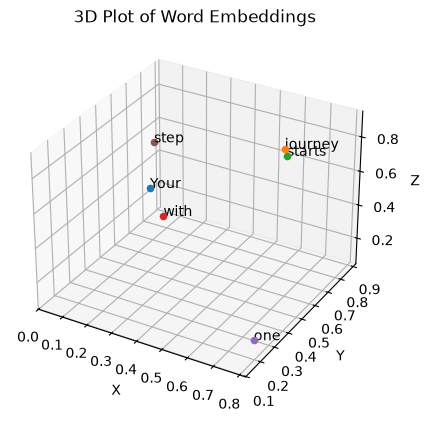

In [4]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

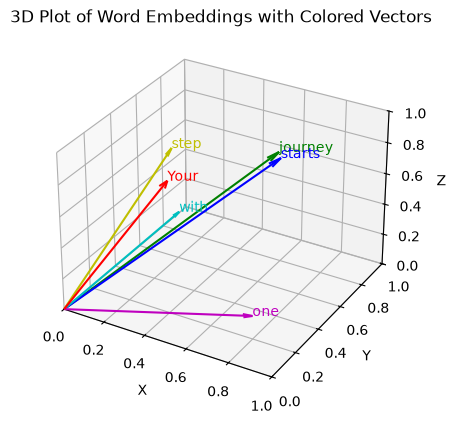

In [5]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()


In [16]:
# # each row rep a word and each column represents an embedding dim

# we will calculate the attention score for the 'journey' word
query = inputs[1]
atten_score_2 = torch.empty(inputs.shape[0])

for i,x_i in enumerate(inputs):
    atten_score_2[i] = torch.dot(x_i,query)

print(atten_score_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [19]:
# normalize using the softmax 
attn_weights_2 = torch.softmax(atten_score_2,dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1618, 0.1787, 0.1779, 0.1595, 0.1570, 0.1650])
Sum: tensor(1.0000)


Now, we can extend this computation to calculate attention weights and context vectors for all inputs.

First, we add an additional for-loop to compute the dot products for all pairs of inputs.

In [24]:
# baisc implementation of the atten of all the words using the loops
atten_score = torch.empty(6,6)

for i,x_i in enumerate(inputs):
    for l,x_l in enumerate(inputs):
        atten_score[i,l] = torch.dot(x_i,x_l)
print(atten_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


### Direct Mathemetical Method for calculating the atten_score between inputs Quary & Key value pair 

In [25]:
atten_score = torch.empty(6,6)

atten_score = inputs @ inputs.T

In [26]:
atten_score

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])

In [28]:
# normalize 

attn_weights = torch.softmax(atten_score, dim=0)
print(attn_weights)

tensor([[0.2098, 0.1385, 0.1390, 0.1435, 0.1526, 0.1385],
        [0.2006, 0.2379, 0.2369, 0.2074, 0.1958, 0.2184],
        [0.1981, 0.2333, 0.2326, 0.2046, 0.1975, 0.2128],
        [0.1242, 0.1240, 0.1242, 0.1462, 0.1367, 0.1420],
        [0.1220, 0.1082, 0.1108, 0.1263, 0.1879, 0.0988],
        [0.1452, 0.1581, 0.1565, 0.1720, 0.1295, 0.1896]])


### IMPLEMENTING SELF ATTENTION WITH TRAINABLE WEIGHTS

In [31]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

In [32]:
print(inputs.shape)
print(input)

torch.Size([6, 3])


In [33]:
# input shape and the output shape 
# GPT like models have same input and output vectors shape

x_2 = inputs[1] # calculate the attention score for the journey word
d_in = inputs.shape[1] # 3
d_out = 2 


In [34]:
torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in,d_out))
W_key = torch.nn.Parameter(torch.rand(d_in,d_out))
W_value = torch.nn.Parameter(torch.rand(d_in,d_out))

print(W_query)
print(W_key)
print(W_value)

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]], requires_grad=True)
Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]], requires_grad=True)
Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]], requires_grad=True)


In [35]:
# calculate the query, key and value matrix --> for the word Journey# 
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value

print(query_2)

tensor([0.4306, 1.4551], grad_fn=<SqueezeBackward4>)


In [36]:
# Calculate the Matrix for all the inputs (q,k,v)

queries = inputs @ W_query
keys = inputs @ W_key
values = inputs @ W_value

print("keys.shape:", keys.shape)

print("values.shape:", values.shape)

print("queries.shape:", queries.shape)

keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])
queries.shape: torch.Size([6, 2])


The output we get is a 6 input token from a 3d vector to 2d vector

In [37]:
# compute the attention score for W22(journey word)
query_journey = queries[1]

attention_scores_2 = query_journey @ keys.T
print(attention_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
       grad_fn=<SqueezeBackward4>)


In [38]:
# attention scores for the inputs --> q*k.T

# omega --> scale(divide by sqrt(d_k)) --> softmax --> W ---> *(values)
attn_scores = queries @ keys.T
print(attn_scores)

tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]],
       grad_fn=<MmBackward0>)


In [42]:
# softmax and scale the atten_scores 
import numpy as np
d_k = keys.shape[-1]
atten_scores = torch.softmax(attn_scores/np.sqrt(d_k),dim=1)
print(atten_scores)

tensor([[0.1551, 0.2104, 0.2059, 0.1413, 0.1074, 0.1799],
        [0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
        [0.1503, 0.2256, 0.2192, 0.1315, 0.0914, 0.1819],
        [0.1591, 0.1994, 0.1962, 0.1477, 0.1206, 0.1769],
        [0.1610, 0.1949, 0.1923, 0.1501, 0.1265, 0.1752],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]],
       grad_fn=<SoftmaxBackward0>)


In [43]:
# compute the value to the W after softmax 

context_vector = atten_scores @ values
print(context_vector)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


# Implementing the Self Attention using class and functions

In [46]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

Insted of nn.Parameters --> we could use the nn.Linear --> more stable and more effective --> weights will be learned during back propagation 

In [55]:
class SelfAttention_v1(nn.Module):
    def __init__(self,d_in,d_out,qkv_bias = False):
        super().__init__()
        self.W_query = nn.Linear(d_in,d_out,bias = qkv_bias) # nn.Parameters
        self.W_key = nn.Linear(d_in,d_out,bias = qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias = qkv_bias)
    def forward(self,x):
        # nn.Linear automatically calculate the multiplication and automatically applies the transformation
        keys = self.W_key(x)  # x @ self.W_key --> when nn.Parameters is used 
        queries = self.W_query(x) # x @ self.W_query --> when nn.Parameters is used
        values = self.W_value(x) # x @ self.W_value --> when nn.Parameters is used
 
        attn_score = queries @ keys.T # omega
        atten_weights = torch.softmax(
            attn_score/keys.shape[-1]**0.5,dim = -1)
        context_vec = atten_weights @ values
        return context_vec

In [56]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in,d_out)
print(sa_v1(inputs))

tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)


# Hidding Future Tokens using the Casual Attention

### Set the weights above the diagonal(upper triangular matrix) to be zero --> and then calculate the context vectors 

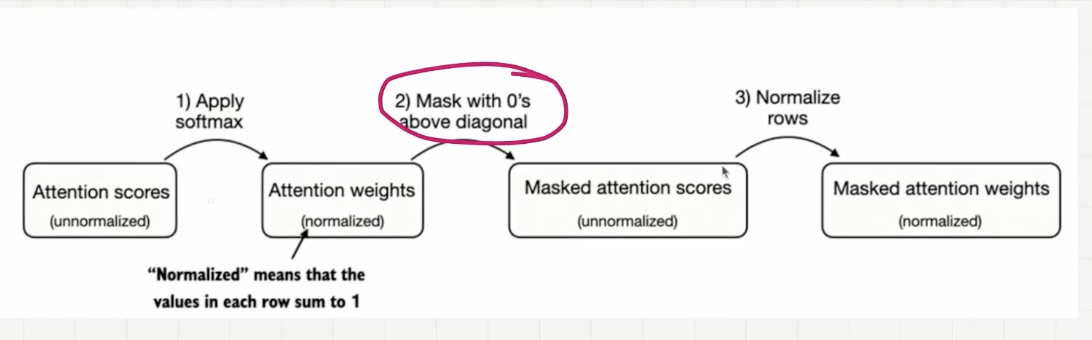
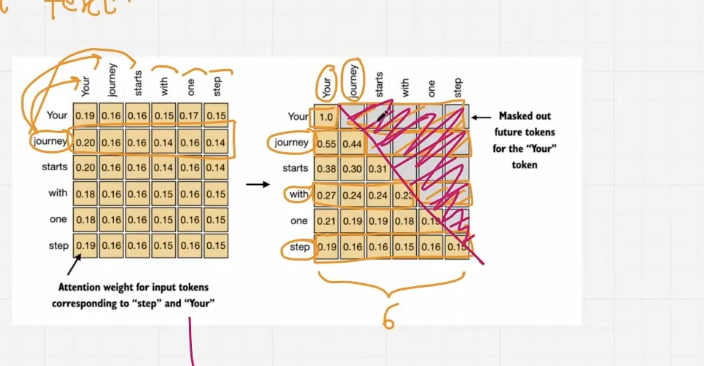Þ

In [58]:
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

In [57]:
queries = sa_v1.W_query(inputs) #A
keys = sa_v1.W_key(inputs)
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[0.1717, 0.1762, 0.1761, 0.1555, 0.1627, 0.1579],
        [0.1636, 0.1749, 0.1746, 0.1612, 0.1605, 0.1652],
        [0.1637, 0.1749, 0.1746, 0.1611, 0.1606, 0.1651],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.1632, 0.1674],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.1639],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)


In [60]:
context_length = attn_weights.shape[0]
context_length#

6

In [69]:
# simple masked atten implement 

# mask the upper triangular matrix
simple_mask = torch.tril(torch.ones(context_length,context_length))
print(simple_mask)

# add this masked mtrix ot the attn_weights
masked_simple = attn_weights*simple_mask
print(masked_simple)

# normalize this masked_matrix
masked_simple_norm = masked_simple/(masked_simple.sum(dim=1,keepdim=True))
print(masked_simple_norm)#

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])
tensor([[0.1717, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1749, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1637, 0.1749, 0.1746, 0.0000, 0.0000, 0.0000],
        [0.1636, 0.1704, 0.1702, 0.1652, 0.0000, 0.0000],
        [0.1667, 0.1722, 0.1721, 0.1618, 0.1633, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<MulBackward0>)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4833, 0.5167, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3408, 0.3402, 0.0000, 0.0000, 0.0000],
        [0.2445, 0.2545, 0.2542, 0.2468, 0.0000, 0.0000],
        [0.1994, 0.2060, 0.2058, 0.1935, 0.1953, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<DivBackward0>)


In [70]:
torch.triu(torch.ones(context_length,context_length))

tensor([[1., 1., 1., 1., 1., 1.],
        [0., 1., 1., 1., 1., 1.],
        [0., 0., 1., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 0., 1., 1.],
        [0., 0., 0., 0., 0., 1.]])

In [71]:
# Masked Attention in the Attention paper (using the -inf and softmax)

# upper triangular matrix --> 1 
mask = torch.triu(torch.ones(context_length,context_length),diagonal=1)
# masked_fill --> check msked.bool() ==1 then replace it by -inf
masked = attn_scores.masked_fill(mask.bool(),-torch.inf)
print(masked)

# mormalize using the softmax fnc
attn_weights = torch.softmax(masked/keys.shape[-1]**0.5,dim=-1)
print(attn_weights)

tensor([[0.3111,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.1655, 0.2602,   -inf,   -inf,   -inf,   -inf],
        [0.1667, 0.2602, 0.2577,   -inf,   -inf,   -inf],
        [0.0510, 0.1080, 0.1064, 0.0643,   -inf,   -inf],
        [0.1415, 0.1875, 0.1863, 0.0987, 0.1121,   -inf],
        [0.0476, 0.1192, 0.1171, 0.0731, 0.0477, 0.0966]],
       grad_fn=<MaskedFillBackward0>)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4833, 0.5167, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3190, 0.3408, 0.3402, 0.0000, 0.0000, 0.0000],
        [0.2445, 0.2545, 0.2542, 0.2468, 0.0000, 0.0000],
        [0.1994, 0.2060, 0.2058, 0.1935, 0.1953, 0.0000],
        [0.1624, 0.1709, 0.1706, 0.1654, 0.1625, 0.1682]],
       grad_fn=<SoftmaxBackward0>)


As we can see based on the output, the values in each row sum to 1, and no further normalization is necessary.

Masking in Transformers sets scores for future tokens to a large negative value, making their influence in the softmax calculation effectively zero.

The softmax function then recalculates attention weights only among the unmasked tokens.

This process ensures no information leakage from masked tokens, focusing the model solely on the intended data.

We could now use the modified attention weights to compute the context vectors via context_vec = attn_weights @ values.

However, in the next section, we first cover another minor tweak to the causal attention mechanism that is useful for reducing overfitting when training LLMs.

# MASKING ADDITIONAL ATTENTION WEIGHTS WITH DROPOUT

In [81]:
import torch
import torch.nn as nn
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape) 

class CausalAttention(nn.Module):

    def __init__(self,d_in,d_out,dropout,context_length,qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('mask',torch.triu(torch.ones(context_length,context_length),diagonal=1))

    def forward(self,x):
        b,n_tokens,d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        atten_scores = queries @ keys.transpose(1,2)
        atten_scores.masked_fill(
            self.mask.bool()[:n_tokens,:n_tokens],-torch.inf)#`:num_tokens` to account for cases where the number of tokens in the batch is smaller than the supported context_size
        atten_weights = torch.softmax(atten_scores/keys.shape[-1]**0.5,dim=-1)
        atten_weights = self.dropout(atten_weights)

        context_vec = atten_weights @ values
        return context_vec
        

torch.Size([2, 6, 3])


In [84]:
torch.manual_seed(123)
d_in = inputs.shape[-1]
d_out = 2
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, 0.1, context_length)
context_vecs = ca(batch)
print(ca)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

CausalAttention(
  (W_query): Linear(in_features=3, out_features=2, bias=False)
  (W_key): Linear(in_features=3, out_features=2, bias=False)
  (W_value): Linear(in_features=3, out_features=2, bias=False)
  (dropout): Dropout(p=0.1, inplace=False)
)
tensor([[[-0.5930, -0.1168],
         [-0.5915, -0.1200],
         [-0.5142, -0.0924],
         [-0.5886, -0.1195],
         [-0.5901, -0.1184],
         [-0.5888, -0.1201]],

        [[-0.4410, -0.1321],
         [-0.5232, -0.0921],
         [-0.3660, -0.0533],
         [-0.5886, -0.1195],
         [-0.5901, -0.1184],
         [-0.5888, -0.1201]]], grad_fn=<UnsafeViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


# IMPLEMENTING MULTI-HEAD ATTENTION WITH WEIGHT SPLITS

In [98]:
a = torch.tensor([[[
[0.2745, 0.6584, 0.2775, 0.8573],
[0.8993, 0.0390, 0.9268, 0.7388],
[0.7179, 0.7058, 0.9156, 0.4340]],
[[0.0772, 0.3565, 0.1479, 0.5331],
[0.4066, 0.2318, 0.4545, 0.9737],
[0.4606, 0.5159, 0.4220, 0.5786]
]]])


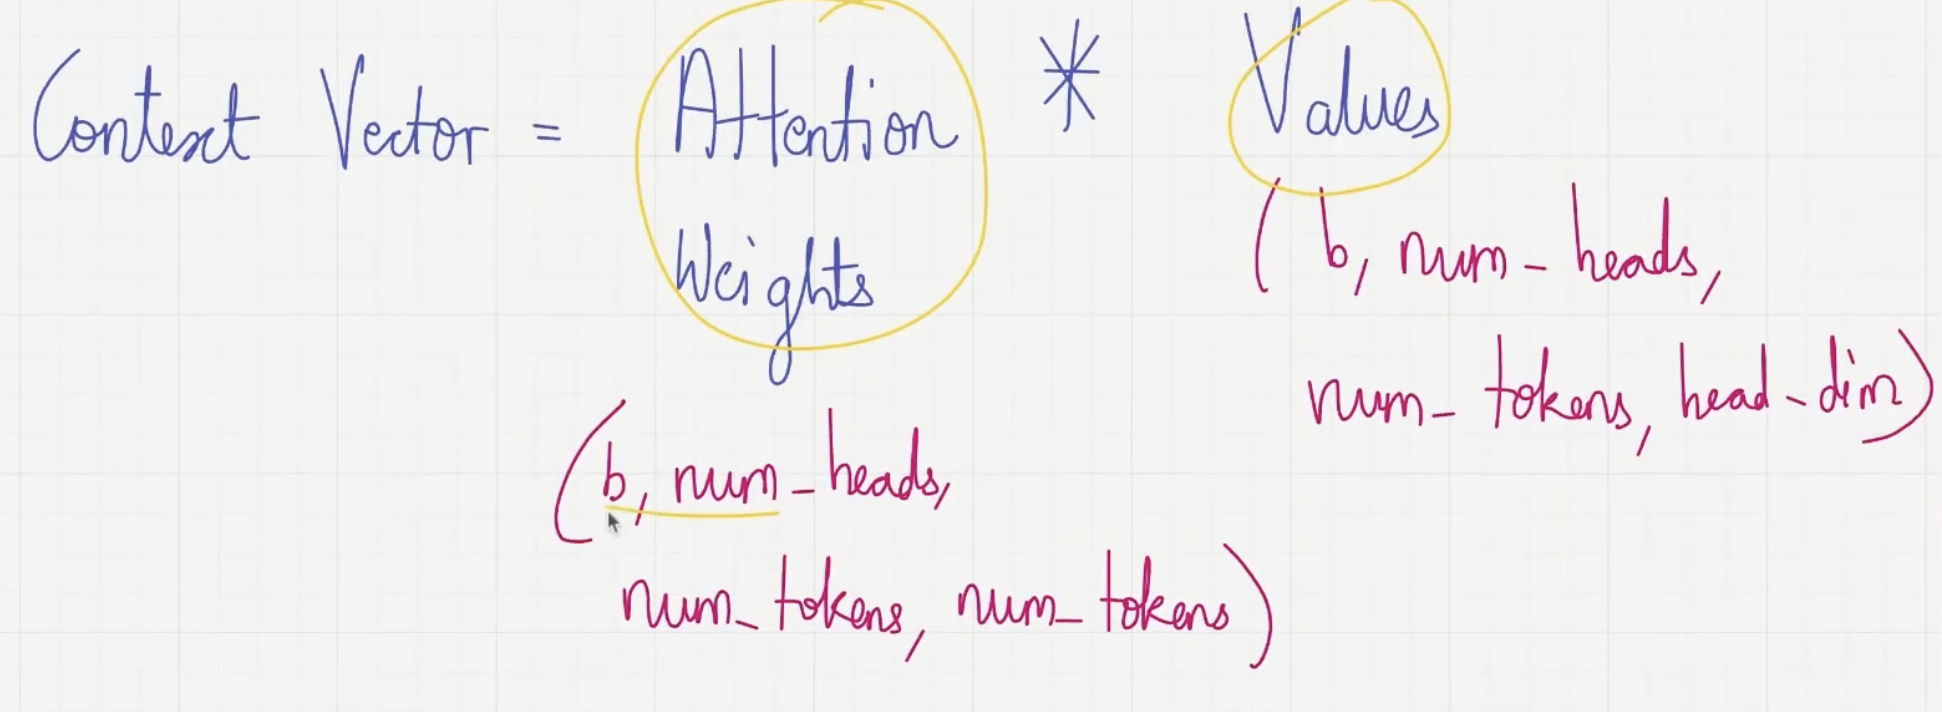

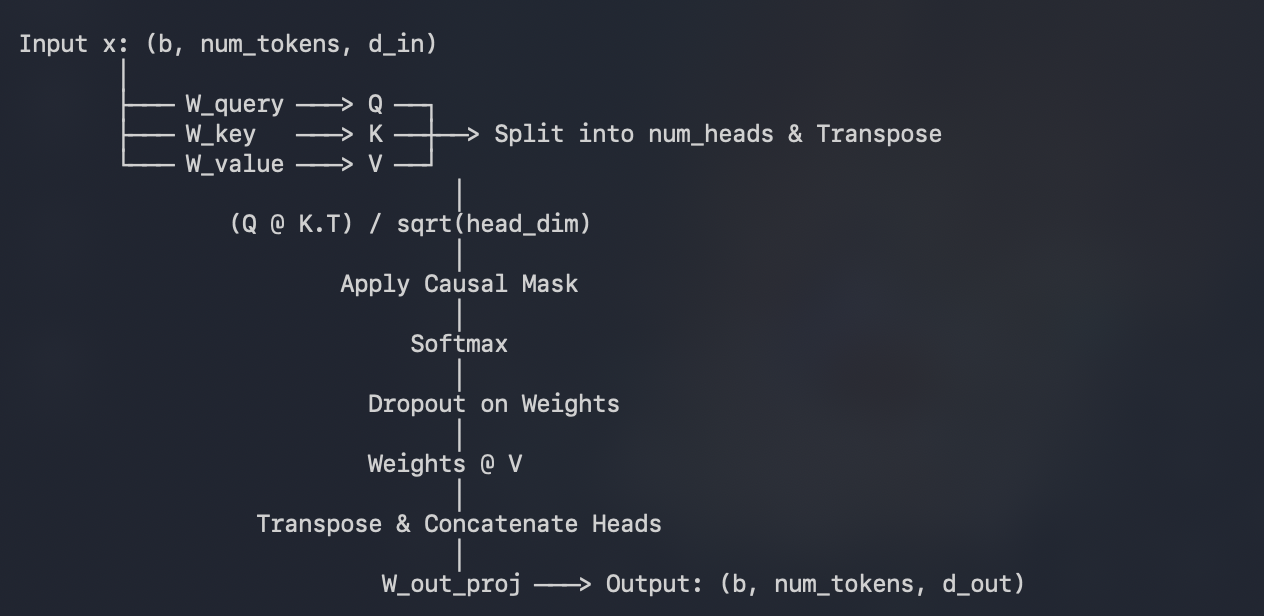

In [110]:
class MultiHeadAttention(nn.Module):

    def __init__(self,d_in,d_out,context_length,dropout,num_heads,qkv_bias = False):
        super().__init__()
        assert (d_out%num_heads==0),"d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.dropout = nn.Dropout(dropout)
        self.head_dim = d_out//num_heads # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)̃
        self.register_buffer(
            'mask',torch.triu(torch.ones(context_length,context_length),diagonal=1)
        )    
    def forward(self,x):
        b,num_tokens,d_in = x.shape

        keys = self.W_key(x) # shape : (b,num_tokens,d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # number of attention heads --> head_dim
        keys = keys.view(b,num_tokens,self.num_heads,self.head_dim)
        queries = queries.view(b,num_tokens,self.num_heads,self.head_dim)
        values = values.view(b,num_tokens,self.num_heads,self.head_dim)

        # transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1,2)
        values = values.transpose(1,2)
        queries = queries.transpose(1,2)

        # atten_score --> masking -->> scale --> softmax
        atten_score = queries @ keys.transpose(-2,-1)
        atten_score.masked_fill_(self.mask.bool()[:num_tokens,:num_tokens],-torch.inf)
        atten_weights = torch.softmax(atten_score/keys.shape[-1]**0.5,dim =-1)
        atten_weights = self.dropout(atten_weights) 

        # context_vectors : (b, num_heads, num_tokens, head_dim) --> (b, num_tokens, num_heads, head_dim)
        context_vectors = (atten_weights @ values).transpose(1,2) 
        
        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vectors = context_vectors.contiguous().view(b, num_tokens, self.d_out)

        return context_vectors
        
        

        

In [111]:
a.shape[-1]

4

In [112]:
torch.manual_seed(123)
batch_size,context_length,d_in = batch.shape

d_out = 2

mha  = MultiHeadAttention(d_in,d_out,context_length,0.2,num_heads = 2)
contvec= mha(batch)
print(contvec)
print(contvec.shape)

tensor([[[-0.5649,  0.0000],
         [-0.7362,  0.0153],
         [-0.7892,  0.0099],
         [-0.7106, -0.1040],
         [-0.6926, -0.1205],
         [-0.4324, -0.1027]],

        [[-0.5649,  0.2770],
         [-0.7362, -0.1229],
         [-0.4826,  0.0103],
         [-0.3666,  0.0068],
         [-0.4896, -0.1766],
         [-0.5768, -0.0698]]], grad_fn=<ViewBackward0>)
torch.Size([2, 6, 2])


## DETAILED EXPLANATION OF THE MULTI-HEAD ATTENTION CLASS

<div class="alert alert-block alert-warning">
The splitting of the query, key, and value tensors, is achieved through tensor reshaping and transposing operations using PyTorch's .view and .transpose methods.

The input is first transformed (via linear layers for queries, keys, and values) and then reshaped to represent multiple heads.
</div>

<div class="alert alert-block alert-warning">
The key operation is to split the d_out dimension into num_heads and head_dim, where head_dim = d_out / num_heads.
</div>

<div class="alert alert-block alert-warning">
This splitting is then achieved using the .view method: a tensor of dimensions (b, num_tokens, d_out) is reshaped to dimension (b, num_tokens, num_heads, head_dim).
</div>

<div class="alert alert-block alert-warning">
The tensors are then transposed to bring the num_heads dimension before the num_tokens dimension, resulting in a shape of (b, num_heads, num_tokens, head_dim).
</div>

<div class="alert alert-block alert-warning">
This transposition is crucial for correctly aligning the queries, keys, and values across the different heads and performing batched matrix multiplications efficiently.
</div>

<div class="alert alert-block alert-warning">
To illustrate this batched matrix multiplication, suppose we have the following example tensor:

Continuing with MultiHeadAttention, after computing the attention weights and context vectors, the context vectors from all heads are transposed back to the shape (b, num_tokens, num_heads, head_dim).

These vectors are then reshaped (flattened) into the shape (b, num_tokens, d_out), effectively combining the outputs from all heads
</div>

<div class="alert alert-block alert-warning">
Additionally, we added a so-called output projection layer (self.out_proj) to MultiHeadAttention after combining the heads, which is not present in the CausalAttention class.
</div>

<div class="alert alert-block alert-warning">
This output projection layer is not strictly necessary, but it is commonly used in many LLM architectures, which is why we added it here for completeness.

Even though the MultiHeadAttention class looks more complicated than the MultiHeadAttentionWrapper due to the additional reshaping and transposition of tensors, it is more efficient.
</div>

<div class="alert alert-block alert-warning">
The reason is that we only need one matrix multiplication to compute the keys, for instance, keys = self.W_key(x) (the same is true for the queries and values).
</div>

<div class="alert alert-block alert-warning">
In the MultiHeadAttentionWrapper, we needed to repeat this matrix multiplication, which is computationally one of the most expensive steps, for each attention head.

The MultiHeadAttention class can be used similar to the SelfAttention and CausalAttention classes we implemented earlier
</div>

## Notes: 
Step 1: Reduce the projection dim to match desired output dim

Step 2: Use a Linear layer to combine head outputs

Step 3: Tensor shape: (b, num_tokens, d_out)

Step 4: We implicitly split the matrix by adding a num_heads dimension. Then we unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)

Step 5: Transpose from shape (b, num_tokens, num_heads, head_dim) to (b, num_heads, num_tokens, head_dim)

Step 6: Compute dot product for each head

Step 7: Mask truncated to the number of tokens

Step 8: Use the mask to fill attention scores

Step 9: Tensor shape: (b, num_tokens, n_heads, head_dim)

Step 10: Combine heads, where self.d_out = self.num_heads * self.head_dim

Step 11: Add an optional linear projection



<div class="alert alert-block alert-warning">

Even though the reshaping (.view) and transposing (.transpose) of tensors inside the
MultiHeadAttention class looks very complicated, mathematically, the
MultiHeadAttention class implements the same concept as the
MultiHeadAttentionWrapper earlier.

</div>

<div class="alert alert-block alert-warning">

On a big-picture level, in the previous MultiHeadAttentionWrapper, we stacked
multiple single-head attention layers that we combined into a multi-head attention layer.


The MultiHeadAttention class takes an integrated approach. 

It starts with a multi-head
layer and then internally splits this layer into individual attention heads

</div>